# 06. Методическая надёжность: что мешает доверять результату и почему это не мешает

## Цель

Усилить методическую часть основного вывода шестью независимыми проверками и зафиксировать иерархию гипотез, чтобы вывод не зависел от выбора метода.

In [ ]:
from pathlib import Path
import json, numpy as np, pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEED = 20240401
rng = np.random.default_rng(SEED)
users = pd.read_csv(ROOT/"data/processed/users_mart.csv", encoding="utf-8-sig")
att   = pd.read_csv(ROOT/"data/processed/payment_attempts_mart.csv", encoding="utf-8-sig")
RES = {}                               

u = users[users.group_eligible].copy()   
op = u[u.opened_any].copy()               
op["s"] = op.success_any.astype(int); op["B"] = (op.assigned_group == "B").astype(int)
op["first"] = pd.to_datetime(op.first_opened_at)
op["week"] = (((op["first"].dt.day - 1)//7) + 1).clip(upper=4)
print("Назначено:", len(u), "| открыли форму:", len(op))
print(op.groupby("assigned_group").s.agg(["sum","count","mean"]))

Назначено: 1503 | открыли форму: 1501
                sum  count     mean
assigned_group                     
A               494    751  0.65779
B               603    750  0.80400


In [2]:
def wilson(k, n, z=1.96):
    p = k/n; c = (p + z*z/(2*n))/(1 + z*z/n)
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/(1 + z*z/n); return c-h, c+h

def newcombe(ka, na, kb, nb):
    pa, pb = ka/na, kb/nb; la, ua = wilson(ka, na); lb, ub = wilson(kb, nb)
    d = pb - pa
    return d, d - np.sqrt((pb-lb)**2 + (ua-pa)**2), d + np.sqrt((ub-pb)**2 + (pa-la)**2)

def ztest(ka, na, kb, nb):
    p = (ka+kb)/(na+nb); se = np.sqrt(p*(1-p)*(1/na + 1/nb))
    z = (kb/nb - ka/na)/se; return z, 2*(1 - stats.norm.cdf(abs(z)))

a, b = op[op.B==0], op[op.B==1]
ka, na, kb, nb = a.s.sum(), len(a), b.s.sum(), len(b)
d, lo, hi = newcombe(ka, na, kb, nb); z, p = ztest(ka, na, kb, nb)
RES["primary"] = dict(ka=int(ka), na=int(na), kb=int(kb), nb=int(nb), pa=ka/na, pb=kb/nb,
                      diff_pp=d*100, ci_lo_pp=lo*100, ci_hi_pp=hi*100, z=z, p=p,
                      rel_uplift=(kb/nb)/(ka/na)-1)
print(f"A {ka}/{na}={ka/na:.4f}  B {kb}/{nb}={kb/nb:.4f}  Δ={d*100:+.2f} п.п. [{lo*100:.2f}; {hi*100:.2f}]  z={z:.2f}  p={p:.2e}")

A 494/751=0.6578  B 603/750=0.8040  Δ=+14.62 п.п. [10.16; 19.00]  z=6.39  p=1.70e-10


## 1. Воронка: переходы между шагами без допущения независимости попыток

В первой версии переходы считались на уровне попыток, где попытки одного клиента считаются независимыми. 

In [3]:
steps = [("Открыл → ввёл реквизиты","opened_any","entered_any"),
         ("Ввёл → подтвердил","entered_any","confirmed_any"),
         ("Подтвердил → оплатил","confirmed_any","success_any")]
trans = []
for name, base, nxt in steps:
    row = {"transition": name}
    for g, d_ in op.groupby("assigned_group"):
        bs = d_[d_[base]]; row[f"n_{g}"] = len(bs); row[f"k_{g}"] = int(bs[nxt].sum())
    dd, l, h = newcombe(row["k_A"], row["n_A"], row["k_B"], row["n_B"])
    _, pv = ztest(row["k_A"], row["n_A"], row["k_B"], row["n_B"])
    row.update(rate_A=row["k_A"]/row["n_A"], rate_B=row["k_B"]/row["n_B"], diff_pp=dd*100, lo_pp=l*100, hi_pp=h*100, p=pv)
    trans.append(row)
trans = pd.DataFrame(trans)
print(trans[["transition","n_A","n_B","rate_A","rate_B","diff_pp","lo_pp","hi_pp","p"]].round(4).to_string(index=False))

             transition  n_A  n_B  rate_A  rate_B  diff_pp  lo_pp   hi_pp      p
Открыл → ввёл реквизиты  751  750  0.8948  0.9427   4.7860 2.0292  7.5886 0.0007
      Ввёл → подтвердил  672  707  0.8170  0.9109   9.3927 5.7965 13.0213 0.0000
   Подтвердил → оплатил  549  644  0.8998  0.9363   3.6518 0.5421  6.8928 0.0208


In [ ]:
att2 = att[att.user_id.notna() & att.assigned_group.isin(["A","B"])].copy()
att2["user_id"] = att2.user_id.astype(int)
cnt = att2.groupby("user_id").agg(o=("opened","sum"), e=("entered","sum"), c=("confirmed","sum"), s=("success","sum"))
cnt = cnt.join(u.set_index("user_id").assigned_group)
def trans_rates(df):
    return np.array([df.e.sum()/df.o.sum(), df.c.sum()/df.e.sum(), df.s.sum()/df.c.sum()])
R = 5000
ga = cnt[cnt.assigned_group=="A"][["o","e","c","s"]].to_numpy(); gb = cnt[cnt.assigned_group=="B"][["o","e","c","s"]].to_numpy()
def rates(m): return np.array([m[:,1].sum()/m[:,0].sum(), m[:,2].sum()/m[:,1].sum(), m[:,3].sum()/m[:,2].sum()])
obs = rates(gb) - rates(ga)
boot = np.empty((R,3))
for i in range(R):
    ia = rng.integers(0, len(ga), len(ga)); ib = rng.integers(0, len(gb), len(gb))
    boot[i] = rates(gb[ib]) - rates(ga[ia])
ci = np.percentile(boot, [2.5, 97.5], axis=0)*100
cl = pd.DataFrame({"transition":[s[0] for s in steps], "diff_pp_attempts":obs*100, "boot_lo":ci[0], "boot_hi":ci[1]})
print(cl.round(2).to_string(index=False))
RES["funnel_user"] = trans.to_dict("records"); RES["funnel_cluster"] = cl.to_dict("records")

             transition  diff_pp_attempts  boot_lo  boot_hi
Открыл → ввёл реквизиты              7.25     4.40    10.07
      Ввёл → подтвердил              8.93     5.48    12.39
   Подтвердил → оплатил              4.72     1.69     7.82


## 2. Вторичное семейство: поправка Холма

In [5]:
fam = []
for _, r in trans.iterrows():
    fam.append((f"Переход: {r.transition}", r.k_A, r.n_A, r.k_B, r.n_B))
def sub(label, d_):
    x = d_[d_.B==0]; y = d_[d_.B==1]
    fam.append((label, x.s.sum(), len(x), y.s.sum(), len(y)))
for v in ["android","ios"]: sub(f"Устройство: {v}", op[op.device_type==v])
for c in ["Москва","СПб","Регион"]: sub(f"Город: {c}", op[op.city==c])
for w in [1,2,3,4]: sub(f"Неделя {w} (по первому открытию)", op[op.week==w])
rows = []
for lab, ka_, na_, kb_, nb_ in fam:
    dd, l, h = newcombe(ka_, na_, kb_, nb_); _, pv = ztest(ka_, na_, kb_, nb_)
    rows.append((lab, int(na_), int(nb_), dd*100, l*100, h*100, pv))
F = pd.DataFrame(rows, columns=["test","nA","nB","diff_pp","lo","hi","p_raw"])
order = F.p_raw.argsort().to_numpy(); m = len(F); adj = np.empty(m); run = 0
for rank, idx in enumerate(order):
    run = max(run, (m-rank)*F.p_raw.iloc[idx]); adj[idx] = min(1, run)
F["p_holm"] = adj; F["signif_holm"] = F.p_holm < 0.05
print(F.round(4).to_string(index=False))
print("Положительных оценок:", int((F.diff_pp>0).sum()), "из", m, "| значимых после Холма:", int(F.signif_holm.sum()))
RES["family"] = F.to_dict("records")

                            test  nA  nB  diff_pp      lo      hi  p_raw  p_holm  signif_holm
Переход: Открыл → ввёл реквизиты 751 750   4.7860  2.0292  7.5886 0.0007  0.0042         True
      Переход: Ввёл → подтвердил 672 707   9.3927  5.7965 13.0213 0.0000  0.0000         True
   Переход: Подтвердил → оплатил 549 644   3.6518  0.5421  6.8928 0.0208  0.0511        False
             Устройство: android 407 369  15.3266  9.0516 21.3991 0.0000  0.0000         True
                 Устройство: ios 344 381  13.6887  7.3137 19.9758 0.0000  0.0002         True
                   Город: Москва 288 306  18.1985 11.0130 25.1727 0.0000  0.0000         True
                      Город: СПб 194 199  15.8654  7.5128 23.9883 0.0002  0.0014         True
                   Город: Регион 268 245   9.5355  1.7042 17.1537 0.0170  0.0511        False
  Неделя 1 (по первому открытию) 266 304  17.9981 11.2621 24.6624 0.0000  0.0000         True
  Неделя 2 (по первому открытию) 203 187   5.6611 -2.9486 14

## 3. Практическая значимость: тест на порог δ

In [6]:
se = np.sqrt(ka/na*(1-ka/na)/na + kb/nb*(1-kb/nb)/nb)
marg = []
for delta in [0, 0.02, 0.03, 0.05, 0.10]:
    zz = ((kb/nb - ka/na) - delta)/se; marg.append((delta*100, zz, 1 - stats.norm.cdf(zz)))
M = pd.DataFrame(marg, columns=["delta_pp","z","p_one_sided"]); print(M.to_string(index=False))
RES["margin"] = M.to_dict("records")

 delta_pp        z  p_one_sided
      0.0 6.475264 4.732326e-11
      2.0 5.589518 1.138506e-08
      3.0 5.146645 1.325935e-07
      5.0 4.260899 1.018033e-05
     10.0 2.046533 2.035196e-02


## 4. Худший случай для исключённых записей и хрупкость вывода

Исключено: платёж 99003 без user_id, пользователь 9001 без группы (попыток нет), конфликтная запись 99002.

In [7]:
scen = []
def add(name, ka_, na_, kb_, nb_):
    d_, l, h = newcombe(ka_, na_, kb_, nb_); _, pv = ztest(ka_, na_, kb_, nb_)
    scen.append((name, d_*100, l*100, h*100, pv))
add("Базовый расчёт", ka, na, kb, nb)
add("Платёж 99003 как неуспешный новый пользователь в B", ka, na, kb, nb+1)
c99002 = att[att.payment_id==99002].iloc[0]; uid = int(c99002.user_id)
us_ok = bool(u[u.user_id==uid].success_any.iloc[0]); other = att[(att.user_id==uid)&(att.payment_id!=99002)].success.any()
print("Пользователь 1010: успех только из 99002?", us_ok and not other)
if us_ok and not other: add("Платёж 99002 исключён (у пользователя 1010 нет других успехов)", ka-1, na, kb, nb)
ka_i = int(u[u.assigned_group=="A"].success_any.sum()); kb_i = int(u[u.assigned_group=="B"].success_any.sum())
na_i = int((u.assigned_group=="A").sum()); nb_i = int((u.assigned_group=="B").sum())
add("ITT: базовый расчёт (все назначенные)", ka_i, na_i, kb_i, nb_i)
add("ITT: пользователь 9001 без группы и попыток — как успех в A", ka_i+1, na_i+1, kb_i, nb_i)
S = pd.DataFrame(scen, columns=["scenario","diff_pp","lo","hi","p"]); print(S.round(3).to_string(index=False))
# индекс хрупкости
fi = None
for k in range(0, kb):
    if ztest(ka, na, kb-k, nb)[1] >= 0.05: fi = k; break
print("Индекс хрупкости: нужно перевернуть", fi, "успехов в B (из", kb, ") → p ≥ 0,05")
RES["worst_case"] = S.to_dict("records"); RES["fragility_index"] = int(fi)

Пользователь 1010: успех только из 99002? True
                                                      scenario  diff_pp     lo     hi   p
                                                Базовый расчёт   14.621 10.162 19.004 0.0
            Платёж 99003 как неуспешный новый пользователь в B   14.514 10.053 18.900 0.0
Платёж 99002 исключён (у пользователя 1010 нет других успехов)   14.754 10.292 19.139 0.0
                         ITT: базовый расчёт (все назначенные)   14.601 10.140 18.987 0.0
   ITT: пользователь 9001 без группы и попыток — как успех в A   14.556 10.097 18.939 0.0
Индекс хрупкости: нужно перевернуть 75 успехов в B (из 603 ) → p ≥ 0,05


## 5. Перестановочный тест

Без параметрических допущений метки A/B случайно перемешиваются между пользователями, считается разность долей.

In [8]:
s_arr = op.s.to_numpy(); g_arr = op.B.to_numpy(); n = len(op); nB = g_arr.sum()
obs_d = s_arr[g_arr==1].mean() - s_arr[g_arr==0].mean()
RP = 50_000; null = np.empty(RP); chunk = 5_000
for i in range(0, RP, chunk):
    idx = np.argsort(rng.random((chunk, n)), axis=1)
    sh = g_arr[idx]
    null[i:i+chunk] = (s_arr*sh).sum(1)/nB - (s_arr*(1-sh)).sum(1)/(n-nB)
p_perm = (np.sum(np.abs(null) >= abs(obs_d)) + 1)/(RP + 1)
# стратифицированная по устройству
dev = op.device_type.to_numpy(); RS = 20_000; null_s = np.empty(RS)
strata = [np.where(dev==v)[0] for v in np.unique(dev)]
for r in range(RS):
    gg = g_arr.copy()
    for ix in strata: gg[ix] = rng.permutation(g_arr[ix])
    null_s[r] = s_arr[gg==1].mean() - s_arr[gg==0].mean()
p_perm_s = (np.sum(np.abs(null_s) >= abs(obs_d)) + 1)/(RS + 1)
print(f"Наблюдаемая разность {obs_d*100:.2f} п.п.; макс. |Δ| в нулевом распределении: {np.abs(null).max()*100:.2f} п.п.")
print(f"p (перестановка, {RP}) < {p_perm:.1e}; p (стратиф. по устройству, {RS}) < {p_perm_s:.1e}")
RES["permutation"] = dict(R=RP, p_upper=p_perm, R_strat=RS, p_strat_upper=p_perm_s, null_max_pp=float(np.abs(null).max()*100), obs_pp=obs_d*100)

Наблюдаемая разность 14.62 п.п.; макс. |Δ| в нулевом распределении: 9.56 п.п.
p (перестановка, 50000) < 2.0e-05; p (стратиф. по устройству, 20000) < 5.0e-05


## 6. Байесовская оценка

In [9]:
N = 400_000
pa_s = rng.beta(1+ka, 1+na-ka, N); pb_s = rng.beta(1+kb, 1+nb-kb, N); dlt = pb_s - pa_s
bay = dict(P_B_gt_A=float((dlt>0).mean()), P_gt_3pp=float((dlt>0.03).mean()), P_gt_5pp=float((dlt>0.05).mean()),
           ci_lo_pp=float(np.percentile(dlt, 2.5)*100), ci_hi_pp=float(np.percentile(dlt, 97.5)*100),
           median_pp=float(np.median(dlt)*100), exp_loss_choose_B_pp=float(np.mean(np.maximum(pa_s-pb_s, 0))*100))
print(bay); RES["bayes"] = bay

{'P_B_gt_A': 1.0, 'P_gt_3pp': 1.0, 'P_gt_5pp': 0.999985, 'ci_lo_pp': 10.157440131356248, 'ci_hi_pp': 19.00073643024082, 'median_pp': 14.589349438881193, 'exp_loss_choose_B_pp': 0.0}


## 7. Баланс групп: SMD, день недели и час

Стандартизованная разность средних для ковариат.

In [10]:
def smd(x, y):
    return (np.mean(y)-np.mean(x))/np.sqrt((np.var(x, ddof=1)+np.var(y, ddof=1))/2)
bal = []
A_, B_ = u[u.assigned_group=="A"], u[u.assigned_group=="B"]
bal.append(("iOS (доля)", smd((A_.device_type=="ios").astype(float), (B_.device_type=="ios").astype(float))))
for c in ["Москва","СПб","Регион"]:
    bal.append((f"Город: {c}", smd((A_.city==c).astype(float), (B_.city==c).astype(float))))
bal.append(("Возраст (валидные)", smd(A_.age_valid.dropna(), B_.age_valid.dropna())))
Bal = pd.DataFrame(bal, columns=["covariate","smd"]); print(Bal.round(3).to_string(index=False))
op["dow"] = op["first"].dt.dayofweek; op["hour"] = op["first"].dt.hour
p_dow = stats.chi2_contingency(pd.crosstab(op.assigned_group, op.dow))[1]
p_hr  = stats.chi2_contingency(pd.crosstab(op.assigned_group, pd.cut(op.hour, [-1,5,11,17,23])))[1]
print(f"День недели первого открытия: χ² p = {p_dow:.3f}; время суток (4 блока): χ² p = {p_hr:.3f}")
RES["balance"] = dict(smd=Bal.to_dict("records"), p_dow=float(p_dow), p_hour=float(p_hr))

         covariate    smd
        iOS (доля)  0.103
     Город: Москва  0.050
        Город: СПб  0.013
     Город: Регион -0.061
Возраст (валидные) -0.011
День недели первого открытия: χ² p = 0.235; время суток (4 блока): χ² p = 0.524


## 8. Сопоставимые оценки основной гипотезы


In [11]:
rows = [("Основная: открывшие форму", d*100, lo*100, hi*100)]
na_i = (u.assigned_group=="A").sum(); nb_i = (u.assigned_group=="B").sum()
ka_i = u[u.assigned_group=="A"].success_any.sum(); kb_i = u[u.assigned_group=="B"].success_any.sum()
di, li, hi_ = newcombe(ka_i, na_i, kb_i, nb_i); rows.append(("ITT: все назначенные", di*100, li*100, hi_*100))
first = att2.sort_values("step1_opened").groupby("user_id").first()
fa_, fb_ = first[first.assigned_group=="A"].success, first[first.assigned_group=="B"].success
df_, lf, hf = newcombe(fa_.sum(), len(fa_), fb_.sum(), len(fb_)); rows.append(("Только первая попытка", df_*100, lf*100, hf*100))
dd_ = op.dropna(subset=["city"]).copy()
def ate(x):
    m = smf.logit("s ~ B + C(device_type) + C(city)", data=x).fit(disp=0)
    return (m.predict(x.assign(B=1)).mean() - m.predict(x.assign(B=0)).mean())*100
pt = ate(dd_); bsr = [ate(dd_.sample(len(dd_), replace=True, random_state=int(rng.integers(1e9)))) for _ in range(500)]
rows.append(("Логит: поправка на устройство и город", pt, np.percentile(bsr, 2.5), np.percentile(bsr, 97.5)))
T = pd.DataFrame(rows, columns=["estimate","diff_pp","lo","hi"]); print(T.round(2).to_string(index=False))
RES["sensitivity"] = T.to_dict("records")
mi = smf.logit("s ~ B*C(device_type)", data=dd_).fit(disp=0); mc = smf.logit("s ~ B*C(city)", data=dd_).fit(disp=0); m0 = smf.logit("s ~ B + C(city)", data=dd_).fit(disp=0)
RES["interaction"] = dict(device_p=float(mi.pvalues.filter(like=":").iloc[0]), city_p=float(1 - stats.chi2.cdf(2*(mc.llf - m0.llf), 2)))
print(RES["interaction"])

                             estimate  diff_pp    lo    hi
            Основная: открывшие форму    14.62 10.16 19.00
                 ITT: все назначенные    14.60 10.14 18.99
                Только первая попытка    14.87  9.90 19.74
Логит: поправка на устройство и город    14.54 10.25 19.02
{'device_p': 0.8036475302724456, 'city_p': 0.1988544033229218}


## 9. Графики методических проверок

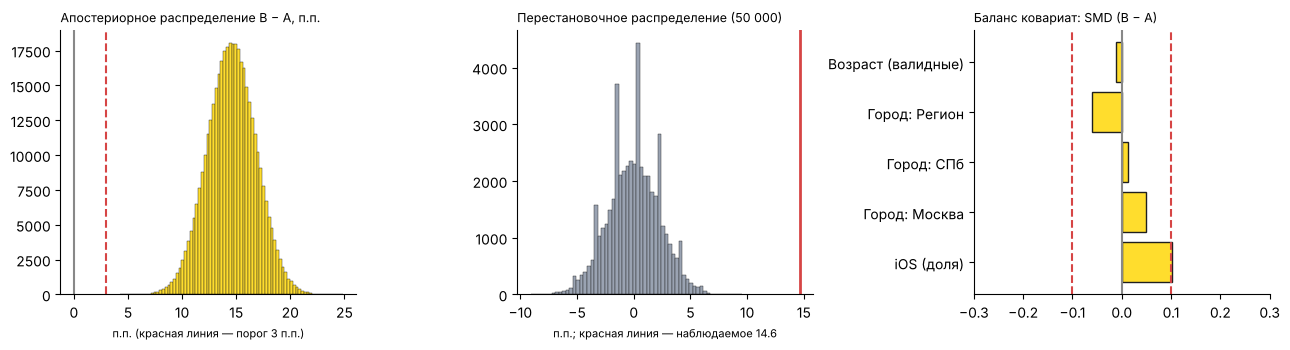

8852

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(dlt*100, bins=80, color="#FFDD2D", edgecolor="#1F1F1F", linewidth=.3); ax[0].axvline(3, color="#D64545", ls="--"); ax[0].axvline(0, color="#888")
ax[0].set_title("Апостериорное распределение B − A, п.п.", fontsize=9, loc="left"); ax[0].set_xlabel("п.п. (красная линия — порог 3 п.п.)", fontsize=8)
ax[1].hist(null*100, bins=60, color="#9AA3B2", edgecolor="#1F1F1F", linewidth=.3); ax[1].axvline(obs_d*100, color="#D64545", lw=2)
ax[1].set_title("Перестановочное распределение (50 000)", fontsize=9, loc="left"); ax[1].set_xlabel(f"п.п.; красная линия — наблюдаемое {obs_d*100:.1f}", fontsize=8)
ax[2].barh(Bal.covariate, Bal.smd, color="#FFDD2D", edgecolor="#1F1F1F"); ax[2].axvline(0, color="#888"); ax[2].axvline(0.1, color="#D64545", ls="--"); ax[2].axvline(-0.1, color="#D64545", ls="--")
ax[2].set_xlim(-0.3, 0.3); ax[2].set_title("Баланс ковариат: SMD (B − A)", fontsize=9, loc="left")
for a_ in ax: a_.spines[["top","right"]].set_visible(False)
fig.tight_layout(); (ROOT/"visualizations").mkdir(exist_ok=True)
fig.savefig(ROOT/"visualizations/methodology_checks.png", dpi=170); plt.show()
(ROOT/"reports/methodology_results.json").write_text(json.dumps(RES, ensure_ascii=False, indent=2, default=float), encoding="utf-8")